# UrbanHub : jumeau numérique urbain

**Projet Big Data · Smart City**. Collecter, stocker, analyser et exploiter les données d'une ville moderne.

| Partie | Flux | Source | Thème |
|---|---|---|---|
| 1 | **Batch** | NOAA Global Hourly | Météo historique (5 ans, stations françaises) |
| 2 | **Streaming** | CityBikes API | Vélos en libre-service, relevés toutes les 2 min 30 |
| 3 | **IoT** | OpenAQ API | Capteurs de pollution (PM2.5, PM10, NO₂, O₃, CO) |
| 4 | **Croisé** | Les trois | Météo × Mobilité × Air |

Ce notebook **ne fait pas l'ingestion lui-même** : les scripts du package `urbanhub` alimentent le Data Lake et l'entrepôt en continu (voir le `README.md`). Le notebook lit les données stockées, répond à chaque question métier et interprète les résultats.

### Sommaire
0. [Architecture et état de la plateforme](#0)
1. [Partie 1 : Analyse météorologique (Batch)](#1)
2. [Partie 2 : Mobilité urbaine (Streaming)](#2)
3. [Partie 3 : Pollution urbaine (IoT)](#3)
4. [Partie 4 : Analyse croisée](#4)
5. [Conclusion et limites](#5)

<a id="0"></a>
## 0. Architecture et état de la plateforme

```
 01 Sources            02 Ingestion                 03 Stockage (Data Lake MinIO)      04 Traitement          05-06 Analyse
 ─────────────         ───────────────────          ─────────────────────────────      ─────────────          ───────────────
 NOAA (S3)      ──►   batch/ (16 threads)    ──►    bronze/noaa/*.csv.gz          ──►  nettoyage pandas  ─┐
 CityBikes API  ──►   streaming/ (150 s)     ──►    bronze/citybikes/*.json.gz    ──►  normalisation     ─┼─► PostgreSQL ──► Notebook
 OpenAQ API     ──►   iot/ (15 min, msgs)    ──►    bronze/openaq/*.jsonl.gz      ──►  conversion µg/m³  ─┤   (schéma        Metabase
 Open-Meteo     ──►   enrichment/            ──►    silver/weather_hourly/*.parquet                      ─┘    urbanhub)
```

- **Bronze** (MinIO) : données brutes, telles que reçues. On peut tout retraiter à partir de là.
- **Silver** (MinIO, Parquet) : données nettoyées et typées.
- **Gold** (PostgreSQL) : tables structurées (`weather_hourly`, `bike_status`, `air_measurement`…) et vues d'indicateurs (`v_weather_city_daily`, `v_bike_status`, `v_air_city_hourly`…) consommées par ce notebook et par Metabase.

In [1]:
import io
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from urbanhub import config
from urbanhub.analysis import cross as X
from urbanhub.analysis import data
from urbanhub.analysis import mobility as M
from urbanhub.analysis import plots
from urbanhub.analysis import pollution as P
from urbanhub.analysis import weather as W
from urbanhub.storage import DataLake, Warehouse

plots.setup()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.2f}".format)

lake, wh = DataLake(), Warehouse()
wh.init_schema()  # idempotent : crée les tables/vues si besoin


def say(text: str) -> None:
    # Affiche une phrase de synthèse calculée à partir des données
    display(Markdown(f"> {text}"))

In [2]:
print("Data Lake MinIO (bucket « urbanhub »)")
display(lake.summary())
print("Entrepôt PostgreSQL (schéma « urbanhub »)")
display(wh.table_counts())

Data Lake MinIO (bucket « urbanhub »)


,zone,source,fichiers,taille_mo
0,bronze,citybikes,80,2.20
1,bronze,noaa,127,77.70
2,bronze,open-meteo,11,0.10
3,silver,weather_hourly,127,14.90


Entrepôt PostgreSQL (schéma « urbanhub »)


,table_name,lignes_estimees
0,air_location,0
1,air_measurement,0
2,air_sensor,0
3,bike_station,3373
4,bike_status,18220
5,weather_daily,38902
6,weather_hourly,917556
7,weather_recent,8041
8,weather_station,36


### Lancer les ingestions

Les collectes se lancent normalement **en ligne de commande** (et tournent en continu) :

```bash
python -m urbanhub batch --cities-only        # Partie 1 (ou sans option : toutes les stations FR)
python -m urbanhub bikes                      # Partie 2 : boucle infinie toutes les 150 s
python -m urbanhub air-backfill --days 60     # Partie 3 : historique
python -m urbanhub air                        # Partie 3 : flux IoT toutes les 15 min
python -m urbanhub weather-recent             # complément météo pour la Partie 4
```

Pour une démonstration rapide depuis le notebook, passez `RUN_INGESTION = True`.

In [3]:
RUN_INGESTION = False

if RUN_INGESTION:
    from urbanhub.batch import pipeline
    from urbanhub.enrichment import open_meteo
    from urbanhub.streaming import collector as bikes_collector

    pipeline.run(cities_only=True)
    bikes_collector.run(once=True)
    open_meteo.run()
    if config.OPENAQ_API_KEY:
        from urbanhub.iot import backfill
        backfill.run(days=60)

<a id="1"></a>
# Partie 1 : Analyse météorologique urbaine (flux Batch)

**Source** : NOAA Global Hourly, des observations horaires de stations météo du monde entier.
L'index `https://www.ncei.noaa.gov/data/global-hourly/access/` redirige aujourd'hui vers le bucket S3 public de la NOAA, avec la même arborescence `{année}/{station}.csv`.

## 1.1 Ingestion : téléchargement parallèle

`urbanhub/batch/` :
1. `noaa_stations.py` lit l'inventaire `isd-history.csv` et garde les stations `CTRY = FR` situées en métropole. Chacune est rattachée à la grande ville la plus proche (≤ 30 km).
2. Le script liste les fichiers réellement publiés pour les **5 dernières années disponibles**. L'archive publique s'arrête en **août 2025**, d'où la fenêtre 2021-2025.
3. `noaa_download.py` télécharge **en parallèle** avec un `ThreadPoolExecutor` (16 threads par défaut, une session HTTP par thread, retries automatiques). Il n'y a **aucun téléchargement un par un**.
4. Les résultats sont consommés au fil de l'eau (`as_completed`) : pendant que les threads téléchargent, le thread principal charge PostgreSQL.

36 stations françaises chargées, dont 36 rattachées à une grande ville
Période couverte : 2021-01-01 -> 2025-08-24


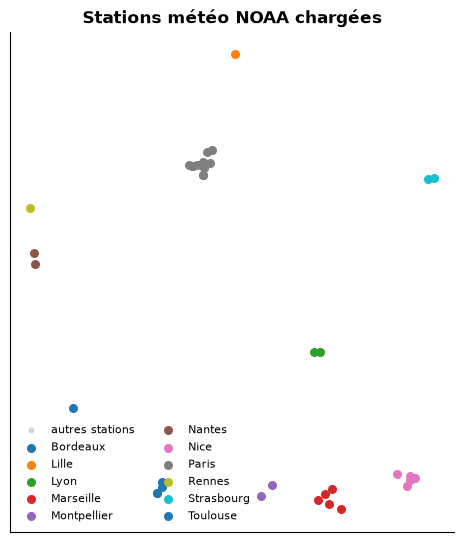

,station_id,name,city,heures
19,07510099999,Bordeaux Merignac,Bordeaux,40335.00
3,07015099999,Lille Lesquin,Lille,40179.00
17,07480099999,Lyon Bron,Lyon,40210.00
18,07481099999,Lyon Saint Exupery,Lyon,40278.00
26,07649099999,Aix Les Milles,Marseille,NaN
30,07656099999,Bec De Laigle,Marseille,26623.00
29,07653099999,Cap Couronne,Marseille,27867.00
28,07652099999,Cap Pomegues,Marseille,NaN
27,07650099999,Marseille Provence,Marseille,40297.00
25,07643099999,Montpellier Mediterranee,Montpellier,40277.00


In [4]:
stations = data.weather_stations()
coverage = wh.read_sql(
    "SELECT station_id, MIN(ts) AS debut, MAX(ts) AS fin, COUNT(*) AS heures FROM {schema}.weather_hourly GROUP BY station_id"
)
stations = stations.merge(coverage, on="station_id", how="left")
print(f"{len(stations)} stations françaises chargées, dont {stations['city'].notna().sum()} rattachées à une grande ville")
print(f"Période couverte : {stations['debut'].min():%Y-%m-%d} -> {stations['fin'].max():%Y-%m-%d}")

fig, ax = plt.subplots(figsize=(7, 6.5))
other = stations[stations["city"].isna()]
ax.scatter(other["longitude"], other["latitude"], s=10, c="#cbd5e1", label="autres stations")
for city, g in stations.dropna(subset=["city"]).groupby("city"):
    ax.scatter(g["longitude"], g["latitude"], s=30, label=city)
ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_title("Stations météo NOAA chargées")
ax.legend(fontsize=8, loc="lower left", ncol=2)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()
display(stations.dropna(subset=["city"]).sort_values(["city", "name"])[["station_id", "name", "city", "heures"]].head(40))

## 1.2 Nettoyage des données

Chaque variable NOAA est encodée sous la forme `"valeur,code_qualité,…"`, avec des facteurs d'échelle et des valeurs sentinelles. Le module `noaa_clean.py` applique ces règles :

| Variable | Brut | Traitement | Unité finale |
|---|---|---|---|
| `temperature` | `TMP = "+0038,1"` | ÷10, `+9999` = manquant | °C |
| `wind_speed` / `wind_direction` | `WND = "210,1,N,0057,1"` | vitesse ÷10, direction `999` = manquant, type `C` = vent calme (vitesse 0) | m/s, degrés |
| `visibility` | `VIS = "003600,1,9,9"` | m → km, `999999` = manquant | km |
| `pressure` | `SLP = "10278,1"` (SYNOP) ou à défaut `MA1 = "10270,1,…"` (QNH METAR) | ÷10, `99999` = manquant | hPa |
| `precipitation` | `AA1/AA2 = "03,0000,9,1"` | hauteur ÷10 divisée par la période (1 à 24 h), la période la plus courte est privilégiée | mm/h |
| `timestamp` | `DATE = "2025-01-01T00:00:00"` | conversion en `datetime` UTC | UTC |

En plus de ces règles par variable :
- les codes qualité suspects ou erronés (`2, 3, 6, 7`) sont rejetés ;
- les rapports de synthèse `SOD`/`SOM` sont exclus, car ce ne sont pas des observations ;
- les valeurs hors bornes physiques (ex. température hors [-50, 50] °C) sont rejetées ;
- les doublons sont supprimés ;
- on agrège en **une ligne par heure** (moyenne ; **moyenne circulaire** pour la direction du vent) ;
- les trous courts (≤ 3 h) de température et de pression sont interpolés.

Démonstration sur un fichier brut lu dans la zone *bronze* du Data Lake :

In [5]:
from urbanhub.batch.noaa_clean import USECOLS, decode_observations, to_hourly

keys = sorted(lake.list_keys("bronze/noaa/"))
key = next((k for k in reversed(keys) if "07149099999" in k), keys[-1])  # Paris-Orly si disponible
raw = pd.read_csv(io.BytesIO(lake.get_bytes(key)), usecols=lambda c: c in USECOLS, dtype=str)
print("Fichier :", key)
print("\nAvant nettoyage :")
display(raw.head(4))

obs = decode_observations(raw)
hourly_demo = to_hourly(obs)
print("Après décodage :")
display(obs.head(4))

print(f"{len(raw):,} lignes brutes -> {len(obs):,} observations -> {len(hourly_demo):,} heures")
print("\nTaux de valeurs manquantes après nettoyage (horaire) :")
display((hourly_demo.drop(columns=["station_id", "ts"]).isna().mean() * 100).round(1).rename("% manquant").to_frame().T)

Fichier : bronze/noaa/year=2025/07149099999.csv.gz

Avant nettoyage :


,STATION,DATE,REPORT_TYPE,WND,VIS,TMP,SLP,AA1,AA2,MA1
0,07149099999,2025-01-01T00:00:00,FM-12,"210,1,N,0057,1","003600,1,9,9","+0038,1","10278,1","03,0000,9,1","06,0000,9,1","99999,9,10165,1"
1,07149099999,2025-01-01T00:00:00,FM-15,"210,1,N,0057,1","006000,1,9,9","+0040,1","99999,9",NaN,NaN,"10270,1,99999,9"
2,07149099999,2025-01-01T00:30:00,FM-15,"210,1,N,0057,1","006000,1,9,9","+0040,1","99999,9",NaN,NaN,"10270,1,99999,9"
3,07149099999,2025-01-01T01:00:00,FM-12,"220,1,N,0057,1","010000,1,9,9","+0036,1","10274,1","01,0000,9,1",NaN,"99999,9,10161,1"


Après décodage :


,station_id,ts,temperature,wind_speed,wind_direction,visibility,pressure,precipitation
0,07149099999,2025-01-01 00:00:00+00:00,3.80,5.70,210.00,3.60,1027.80,0.00
1,07149099999,2025-01-01 00:00:00+00:00,4.00,5.70,210.00,6.00,1027.00,NaN
2,07149099999,2025-01-01 00:30:00+00:00,4.00,5.70,210.00,6.00,1027.00,NaN
3,07149099999,2025-01-01 01:00:00+00:00,3.60,5.70,220.00,10.00,1027.40,0.00


11,414 lignes brutes -> 11,414 observations -> 5,648 heures

Taux de valeurs manquantes après nettoyage (horaire) :


,temperature,wind_speed,wind_direction,visibility,pressure,precipitation
% manquant,0.00,0.70,4.70,0.70,0.00,94.70


> **À noter**
> - La **visibilité** des messages METAR est plafonnée à 10 km (« 9999 »). Les valeurs plus élevées viennent des messages SYNOP.
> - Les **précipitations** ne sont présentes que dans certains messages (souvent toutes les 6 ou 12 h). C'est pourquoi le taux de valeurs manquantes horaires est élevé. Le cumul journalier est *estimé* à partir du taux moyen (mm/h × 24).

In [6]:
daily = data.weather_city_daily()        # vue v_weather_city_daily : moyenne des stations de chaque ville
france = data.weather_france_daily()     # moyenne de toutes les stations chargées
hourly = data.weather_city_hourly(source="noaa")
print(f"Journalier : {len(daily):,} lignes ({daily['city'].nunique()} villes) | horaire : {len(hourly):,} lignes")
daily.head()

Journalier : 18,484 lignes (11 villes) | horaire : 443,182 lignes


,city,day,t_mean,t_min,t_max,wind_mean,wind_max,visibility_mean,visibility_min,pressure_mean,precipitation,n_stations
0,Bordeaux,2021-01-01,2.30,0.00,4.97,3.30,6.17,6.03,1.23,1007.79,6.41,1
1,Bordeaux,2021-01-02,0.99,-2.10,4.00,3.49,5.70,12.73,3.93,1014.80,0.33,1
2,Bordeaux,2021-01-03,2.99,-0.03,7.43,3.94,5.83,14.96,7.43,1012.61,5.74,1
3,Bordeaux,2021-01-04,1.91,-1.00,4.10,3.26,4.93,9.73,4.30,1010.34,0.07,1
4,Bordeaux,2021-01-05,1.68,-1.17,3.10,1.91,4.10,7.45,2.10,1013.33,0.00,1


## Q1. Peut-on identifier des périodes météorologiques anormales ?

**Méthode.** Pour chaque ville, on calcule la *normale* de chaque jour de l'année : la moyenne de la température sur les 5 ans pour ce jour, lissée sur 31 jours. On en déduit l'**anomalie** (écart à la normale en °C) et le **z-score** (anomalie / écart-type habituel). Une **période anormale** est une suite d'au moins 3 jours consécutifs avec |z| ≥ 1,5. En climat stable, environ 7 % des jours dépassent ce seuil dans chaque sens, et trois jours de suite est rare.

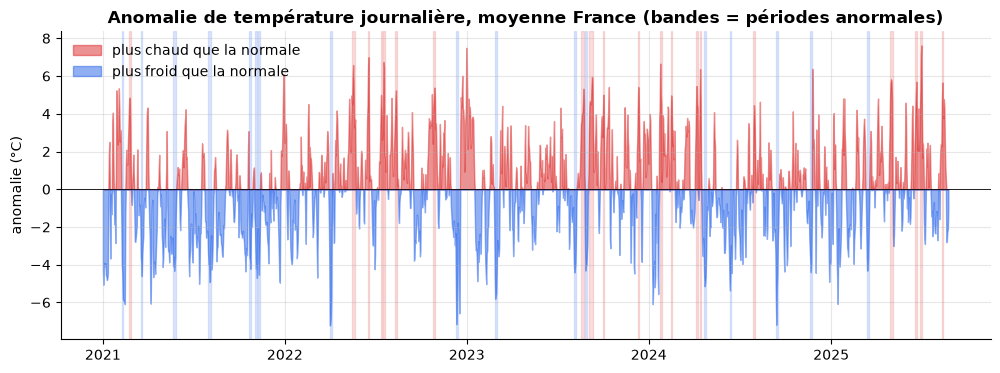

Périodes anormales à l'échelle de la France (les plus longues) :


,type,debut,fin,jours,anomalie_moy_C,z_max
0,chaud,2023-09-04,2023-09-11,8,4.90,2.40
1,chaud,2022-05-15,2022-05-20,6,5.20,2.80
2,chaud,2023-08-19,2023-08-24,6,4.40,2.20
3,froid,2023-02-26,2023-03-02,5,-5.20,2.70
4,chaud,2025-04-29,2025-05-03,5,5.30,2.40
5,froid,2021-07-31,2021-08-04,5,-4.20,2.20
6,froid,2021-05-22,2021-05-26,5,-3.90,1.90
7,froid,2024-09-12,2024-09-15,4,-5.70,2.90
8,froid,2022-12-10,2022-12-13,4,-5.80,2.80
9,chaud,2025-06-28,2025-07-01,4,6.00,2.80


Périodes anormales les plus longues par ville :


,city,type,debut,fin,jours,anomalie_moy_C,z_max
0,Paris,chaud,2023-09-03,2023-09-11,9,6.50,3.00
1,Marseille,chaud,2025-06-27,2025-07-05,9,4.30,2.20
2,Bordeaux,chaud,2022-07-11,2022-07-18,8,6.60,3.40
3,Strasbourg,froid,2022-12-11,2022-12-18,8,-8.20,3.10
4,Lille,froid,2022-12-11,2022-12-18,8,-8.30,3.00
5,Lyon,chaud,2022-05-15,2022-05-22,8,7.00,2.80
6,Rennes,chaud,2023-09-03,2023-09-10,8,6.40,2.80
7,Nice,chaud,2025-06-28,2025-07-05,8,4.00,2.60
8,Nantes,chaud,2023-09-03,2023-09-10,8,5.80,2.50
9,Paris,froid,2022-12-11,2022-12-18,8,-7.50,2.50


In [7]:
anom = W.daily_anomalies(daily)
periods = W.anomalous_periods(anom, z_threshold=1.5, min_days=3)

fr = france.assign(city="France")
anom_fr = W.daily_anomalies(fr)
periods_fr = W.anomalous_periods(anom_fr, z_threshold=1.5, min_days=3)

fig, ax = plt.subplots(figsize=(12, 4))
s = anom_fr.set_index("day")["anomaly"]
ax.fill_between(s.index, 0, s.clip(lower=0), color="#dc2626", alpha=0.5, label="plus chaud que la normale")
ax.fill_between(s.index, 0, s.clip(upper=0), color="#2563eb", alpha=0.5, label="plus froid que la normale")
for _, p in periods_fr.iterrows():
    ax.axvspan(pd.Timestamp(p["debut"]), pd.Timestamp(p["fin"]) + pd.Timedelta(days=1),
               color="#dc2626" if p["type"] == "chaud" else "#2563eb", alpha=0.15)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("anomalie (°C)")
ax.set_title("Anomalie de température journalière, moyenne France (bandes = périodes anormales)")
ax.legend(loc="upper left")
plt.show()

print("Périodes anormales à l'échelle de la France (les plus longues) :")
display(periods_fr.drop(columns="city").head(12))
print("Périodes anormales les plus longues par ville :")
display(periods.head(12))

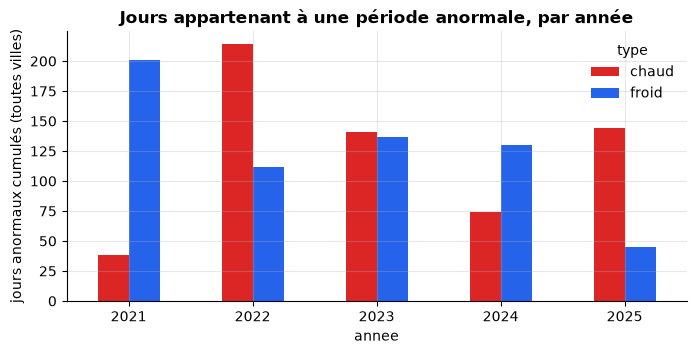

> 37 périodes anormales détectées à l'échelle nationale. La plus longue : épisode **chaud** du 2023-09-04 au 2023-09-11 (8 jours, anomalie moyenne +4.9 °C).

> Bilan toutes villes : 149 périodes chaudes contre 160 froides. Jours anormalement chauds par an : {2021: 38, 2022: 214, 2023: 141, 2024: 74, 2025: 144}.

In [8]:
by_year = periods.assign(annee=pd.to_datetime(periods["debut"]).dt.year).pivot_table(
    index="annee", columns="type", values="jours", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
by_year.plot.bar(ax=ax, color={"chaud": "#dc2626", "froid": "#2563eb"})
ax.set_ylabel("jours anormaux cumulés (toutes villes)")
ax.set_title("Jours appartenant à une période anormale, par année")
plt.xticks(rotation=0)
plt.show()

if not periods_fr.empty:
    top = periods_fr.iloc[0]  # trié par durée puis intensité
    say(f"{len(periods_fr)} périodes anormales détectées à l'échelle nationale. La plus longue : épisode **{top['type']}** "
        f"du {top['debut']} au {top['fin']} ({top['jours']} jours, anomalie moyenne {top['anomalie_moy_C']:+.1f} °C).")
say(f"Bilan toutes villes : {int((periods['type'] == 'chaud').sum())} périodes chaudes contre "
    f"{int((periods['type'] == 'froid').sum())} froides. "
    f"Jours anormalement chauds par an : {by_year.get('chaud', pd.Series(dtype=float)).to_dict()}.")

**Interprétation.**
- Oui, la méthode isole clairement des épisodes anormaux, et ils correspondent à des événements connus :
  - **chaleur tardive de début septembre 2023** : la plus longue à l'échelle nationale, avec 9 jours à +6,5 °C à Paris ;
  - **vague de chaleur de mi-juillet 2022** : Bordeaux à +6,6 °C pendant 8 jours ;
  - **épisode précoce de mai 2022** ;
  - **canicule de fin août 2023** ;
  - **canicule de fin juin / début juillet 2025** : Marseille, Nice ;
  - côté froid, la **vague de froid de mi-décembre 2022** : -8 °C sous la normale à Lille, Strasbourg et Paris.
- Les épisodes touchent souvent **plusieurs villes en même temps** : ce sont des phénomènes synoptiques (dômes de chaleur, descentes d'air polaire), pas des effets locaux.
- **2022** est l'année qui compte le plus de jours anormalement chauds. C'est cohérent avec son statut d'année la plus chaude jamais mesurée en France. À l'inverse, **2021** est dominée par les jours anormalement frais.
- Limite : 5 ans de données donnent une « normale » courte. Une vraie normale climatologique se calcule sur 30 ans. Les anomalies sont donc relatives à 2021-2025, période déjà réchauffée, ce qui sous-estime les épisodes chauds.

## Q2. Existe-t-il une corrélation entre conditions météorologiques et visibilité ?

**Méthode.** On utilise la corrélation de **Spearman** (rangs), adaptée à des relations non linéaires et à une visibilité plafonnée. On la complète par la visibilité moyenne et la part d'heures de **brouillard** (visibilité < 1 km) selon la pluie, le vent, la pression et le mois.

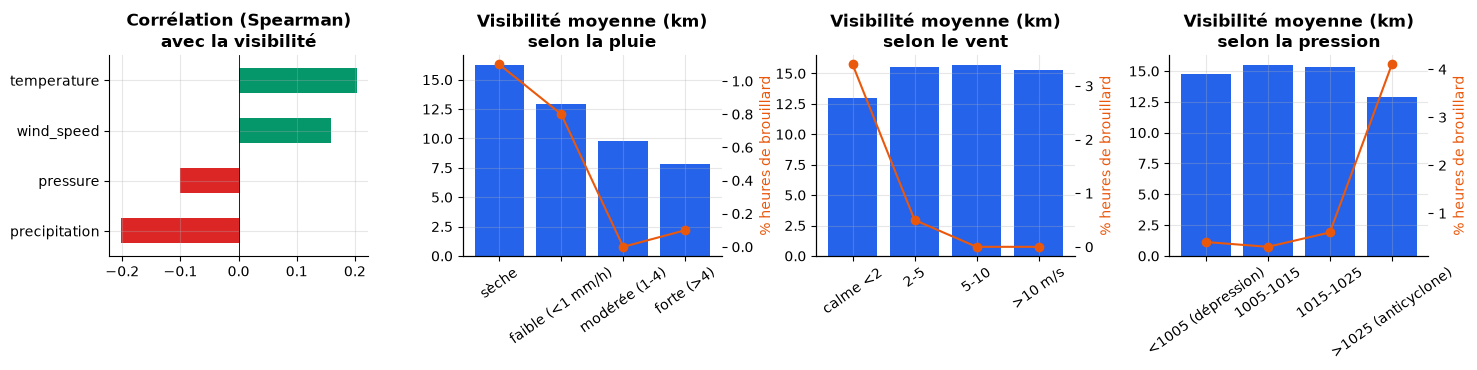

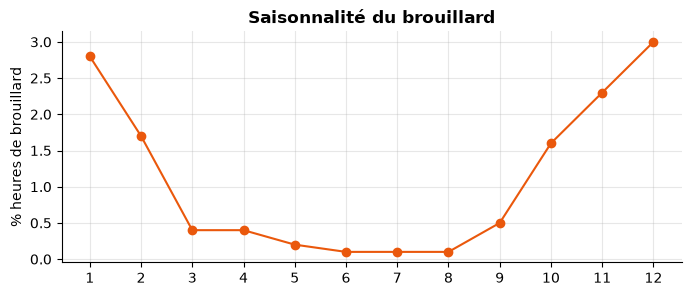

,spearman
precipitation,-0.20
pressure,-0.10
wind_speed,0.16
temperature,0.20


In [9]:
corr_vis = W.visibility_correlations(hourly)
vis = W.visibility_by_condition(hourly)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
corr_vis.plot.barh(ax=axes[0], color=["#dc2626" if v < 0 else "#059669" for v in corr_vis])
axes[0].set_title("Corrélation (Spearman)\navec la visibilité")
axes[0].axvline(0, color="black", lw=0.6)
for ax, key, title in zip(axes[1:], ["pluie", "vent", "pression"], ["selon la pluie", "selon le vent", "selon la pression"]):
    t = vis[key]
    ax.bar(t.index.astype(str), t["visibilite_moy_km"], color=plots.PALETTE["batch"])
    ax2 = ax.twinx()
    ax2.plot(t.index.astype(str), t["part_brouillard"] * 100, color="#ea580c", marker="o")
    ax2.set_ylabel("% heures de brouillard", color="#ea580c")
    ax2.grid(False)
    ax.set_title(f"Visibilité moyenne (km)\n{title}")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
m = vis["mois"]
ax.plot(m.index, m["part_brouillard"] * 100, marker="o", color="#ea580c")
ax.set_xticks(range(1, 13))
ax.set_ylabel("% heures de brouillard")
ax.set_title("Saisonnalité du brouillard")
plt.show()
display(corr_vis.to_frame("spearman"))

In [10]:
p = vis["pression"]["part_brouillard"]
v = vis["vent"]["part_brouillard"]
r = vis["pluie"]["visibilite_moy_km"]
say(f"La pluie réduit la visibilité de {r.iloc[0]:.1f} km (temps sec) à {r.iloc[-1]:.1f} km (pluie forte). "
    f"Le brouillard est {p.iloc[-1] / max(p.iloc[1], 1e-9):.0f} fois plus fréquent sous anticyclone (>1025 hPa) "
    f"qu'en pression normale, et {v.iloc[0] / max(v.iloc[1], 1e-9):.0f} fois plus fréquent par vent calme.")

> La pluie réduit la visibilité de 16.3 km (temps sec) à 7.9 km (pluie forte). Le brouillard est 14 fois plus fréquent sous anticyclone (>1025 hPa) qu'en pression normale, et 7 fois plus fréquent par vent calme.

**Interprétation.**
- **Oui, la visibilité dépend nettement de la météo**, mais la relation n'est pas linéaire, d'où des coefficients de Spearman modestes (|ρ| ≈ 0,1 à 0,2).
- **Précipitations** : c'est la relation la plus directe. Plus il pleut, plus la visibilité baisse (gouttes, embruns, plafond bas).
- **Pression et vent : l'effet « anticyclone »**. Le brouillard se forme surtout par **haute pression et vent calme** : ciel clair la nuit, refroidissement du sol, inversion de température, air stagnant et saturé. C'est l'inverse de l'intuition « beau temps = bonne visibilité ».
- **Température** : corrélation positive. Les journées chaudes sont sèches et brassées, alors que le brouillard est un phénomène des saisons froides (pic d'octobre à janvier, voir la courbe mensuelle).
- Pour un décideur public, ces conditions (anticyclone hivernal + vent calme) sont aussi celles des **épisodes de pollution** : on y revient dans la Partie 4.

## Q3. Quelle est l'évolution saisonnière de la température en France et dans les principales villes ?

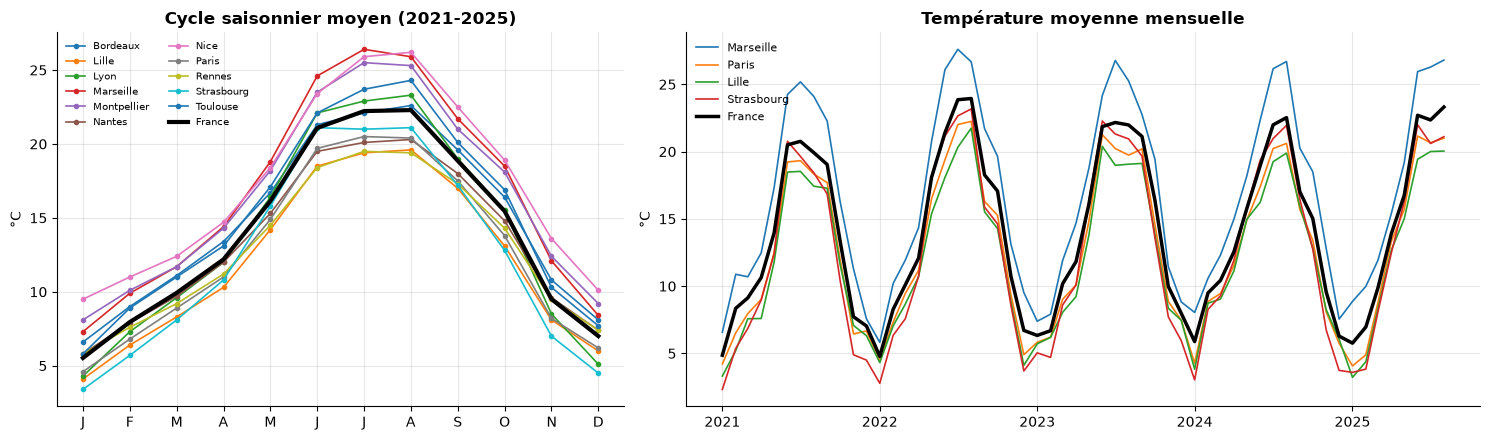

,mois_le_plus_froid_C,mois_le_plus_chaud_C,amplitude_C
city,,,
Marseille,7.30,26.40,19.10
Lyon,4.30,23.30,19.00
Toulouse,5.80,24.30,18.50
Strasbourg,3.40,21.10,17.70
Montpellier,8.10,25.50,17.40
Nice,9.50,26.20,16.70
Bordeaux,6.60,22.60,16.00
Paris,4.60,20.50,15.90
Lille,4.10,19.60,15.50


Température moyenne annuelle (années complètes) :


city,Bordeaux,Lille,Lyon,Marseille,Montpellier,Nantes,Nice,Paris,Rennes,Strasbourg,Toulouse
annee,,,,,,,,,,,
2021,13.79,11.11,12.66,15.82,15.59,12.42,16.49,11.74,11.90,11.04,14.02
2022,15.52,12.45,14.50,17.32,16.99,14.17,17.59,13.24,13.43,12.98,15.82
2023,15.18,12.48,14.40,16.66,16.70,13.98,17.42,13.23,13.38,13.07,15.10
2024,14.57,12.26,13.76,16.65,16.47,12.95,17.34,12.57,12.66,12.62,14.93


In [11]:
clim = W.monthly_climatology(daily)
clim_fr = france.assign(mois=france["day"].dt.month).groupby("mois")["t_mean"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
for city in clim.columns:
    axes[0].plot(clim.index, clim[city], marker=".", lw=1.2, label=city)
axes[0].plot(clim_fr.index, clim_fr, color="black", lw=3, label="France")
axes[0].set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_ylabel("°C")
axes[0].set_title("Cycle saisonnier moyen (2021-2025)")
axes[0].legend(fontsize=7, ncol=2)

monthly = W.seasonal_profile(daily)
monthly_fr = W.seasonal_profile(france, group=None)
for city in ["Marseille", "Paris", "Lille", "Strasbourg"]:
    g = monthly[monthly["city"] == city]
    axes[1].plot(g["month"], g["t_mean"], lw=1.2, label=city)
axes[1].plot(monthly_fr["month"], monthly_fr["t_mean"], color="black", lw=2.5, label="France")
axes[1].set_title("Température moyenne mensuelle")
axes[1].set_ylabel("°C")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

amp = W.seasonal_amplitude(daily)
trend = W.yearly_trend(daily)
display(amp)
print("Température moyenne annuelle (années complètes) :")
display(trend)

In [12]:
warmest_year = trend.mean(axis=1).idxmax()
say(f"Amplitude saisonnière la plus forte : **{amp.index[0]}** ({amp['amplitude_C'].iloc[0]:.1f} °C), la plus faible : "
    f"**{amp.index[-1]}** ({amp['amplitude_C'].iloc[-1]:.1f} °C). Ville la plus chaude en hiver : "
    f"**{clim.loc[1].idxmax()}** ({clim.loc[1].max():.1f} °C en janvier). Année la plus chaude : **{warmest_year}**.")

> Amplitude saisonnière la plus forte : **Marseille** (19.1 °C), la plus faible : **Rennes** (13.7 °C). Ville la plus chaude en hiver : **Nice** (9.5 °C en janvier). Année la plus chaude : **2022**.

**Interprétation.**
- Toutes les villes suivent le même **cycle saisonnier** : minimum en janvier, maximum en juillet-août. Les différences tiennent à trois influences climatiques :
  - **méditerranéenne** (Marseille, Nice, Montpellier) : la plus chaude toute l'année. Nice a l'hiver le plus doux, car la mer amortit les extrêmes et son amplitude reste modérée. Marseille, mesurée à Marignane en retrait de la côte, a des étés très chauds et la plus forte amplitude ;
  - **semi-continentale** (Lyon, Strasbourg) et **Sud-Ouest intérieur** (Toulouse) : forte **amplitude**, avec des hivers froids et des étés chauds. Lyon rivalise avec Marseille ;
  - **océanique** (Rennes, Nantes, Lille) : la plus faible amplitude, avec des étés frais et des hivers doux.
- **Paris** est intermédiaire. Son hiver est un peu plus doux que celui de Lille, en partie grâce à l'îlot de chaleur urbain.
- **D'une année à l'autre**, 2022 est la plus chaude dans quasiment toutes les villes. 2021 est la plus fraîche de la série.

## Q4. Quels sont les jours présentant des conditions météorologiques extrêmes ?

**Seuils retenus** (inspirés des vigilances Météo-France, appliqués à la moyenne des stations de chaque ville) :

| Condition | Critère |
|---|---|
| canicule | T max ≥ 35 °C |
| grand froid | T min ≤ -7 °C |
| vent violent | vent moyen horaire max ≥ 15 m/s (≈ 54 km/h, rafales bien supérieures) |
| fortes pluies | cumul estimé ≥ 30 mm/jour |
| brouillard dense | visibilité min ≤ 200 m |

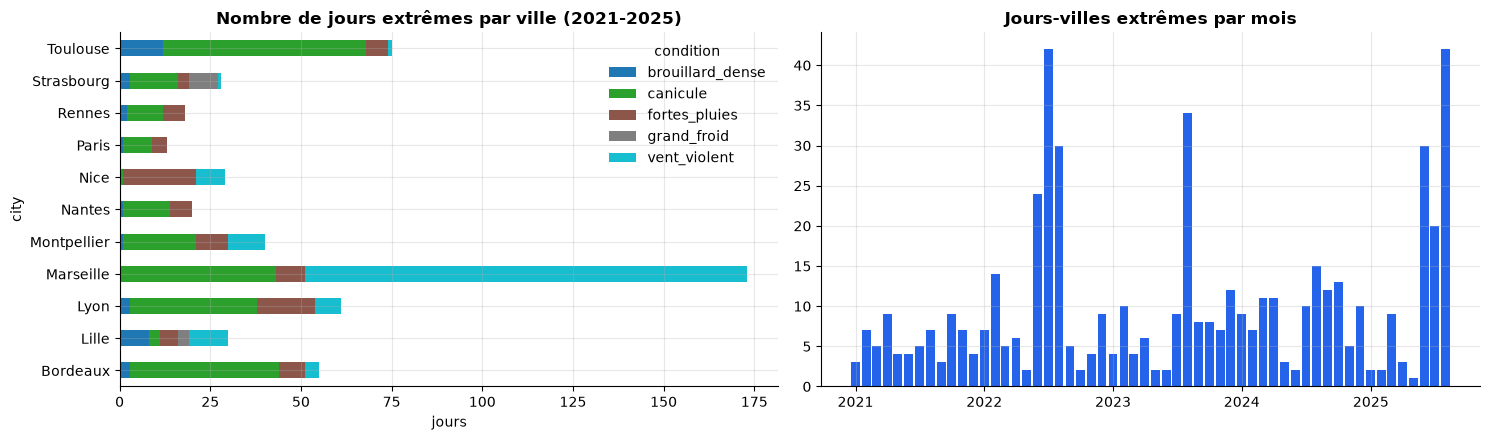

condition,brouillard_dense,canicule,fortes_pluies,grand_froid,vent_violent
city,,,,,
Bordeaux,3,41,7,0,4
Lille,8,3,5,3,11
Lyon,3,35,16,0,7
Marseille,0,43,8,0,122
Montpellier,1,20,9,0,10
Nantes,1,13,6,0,0
Nice,0,1,20,0,8
Paris,1,8,4,0,0
Rennes,2,10,6,0,0


Jours cumulant plusieurs conditions extrêmes, ou les plus intenses :


,city,day,conditions,n_conditions,t_min,t_max,wind_max,precipitation,visibility_min
5337,Marseille,2021-10-30,"vent_violent, fortes_pluies",2,14.90,18.83,16.13,41.53,2.89
7151,Montpellier,2022-03-13,"vent_violent, fortes_pluies",2,3.95,11.10,16.90,37.54,6.49
17764,Toulouse,2023-08-23,canicule,1,23.28,41.66,2.55,0.00,12.86
18470,Toulouse,2025-08-11,canicule,1,21.50,41.33,2.68,NaN,9.90
17765,Toulouse,2023-08-24,canicule,1,26.07,41.25,5.28,0.00,10.52
18471,Toulouse,2025-08-12,canicule,1,22.33,40.17,4.72,NaN,9.90
14004,Rennes,2022-07-18,canicule,1,20.47,40.10,6.37,0.00,11.27
559,Bordeaux,2022-07-18,canicule,1,23.63,39.83,7.87,0.00,9.27
4320,Lyon,2023-08-24,canicule,1,22.98,39.50,10.55,0.00,9.90
1668,Bordeaux,2025-08-11,canicule,1,23.00,39.50,7.70,NaN,9.90


In [13]:
ext = W.extreme_days(daily)
summary = W.extreme_summary(ext)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
summary.plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Nombre de jours extrêmes par ville (2021-2025)")
axes[0].set_xlabel("jours")
by_month = ext.assign(m=ext["day"].dt.to_period("M").dt.to_timestamp()).groupby("m").size()
axes[1].bar(by_month.index, by_month.values, width=25, color=plots.PALETTE["batch"])
axes[1].set_title("Jours-villes extrêmes par mois")
plt.tight_layout()
plt.show()

display(summary)
print("Jours cumulant plusieurs conditions extrêmes, ou les plus intenses :")
display(ext.sort_values(["n_conditions", "t_max"], ascending=False).head(15))

In [14]:
cnt = ext.groupby("day")["city"].nunique().sort_values(ascending=False)
top_day = cnt.index[0]
say(f"{len(ext):,} jours-villes extrêmes au total. Journée la plus généralisée : **{top_day:%d/%m/%Y}** "
    f"({cnt.iloc[0]} villes touchées : {', '.join(ext[ext['day'] == top_day]['city'])}).")

> 540 jours-villes extrêmes au total. Journée la plus généralisée : **18/06/2022** (8 villes touchées : Bordeaux, Lyon, Marseille, Nantes, Paris, Rennes, Strasbourg, Toulouse).

**Interprétation.**
- Les **canicules** (T max ≥ 35 °C) se concentrent sur les étés 2022, 2023 et 2025, et frappent surtout le Sud-Ouest et le Sud-Est : Toulouse (jusqu'à 41,7 °C le 23/08/2023), Marseille, Bordeaux, Lyon. Les journées les plus généralisées (18/06/2022, 18/07/2022, 01/07/2025, avec 8 villes touchées) sont les pics des vagues de chaleur repérées en Q1 : les deux analyses se confirment.
- Le **vent violent** est d'abord un marqueur du **mistral** à Marseille, de loin la ville la plus ventée. Trois de ses cinq stations sont des caps exposés (Cap Couronne, Bec de l'Aigle, Pomègues), ce qui amplifie le signal. Viennent ensuite les tempêtes d'hiver sur Lille et la tramontane à Montpellier.
- Les **fortes pluies** touchent surtout Nice et Lyon, avec un **pic net en septembre-octobre** : ce sont les épisodes méditerranéens et cévenols d'automne.
- Le **brouillard dense** (≤ 200 m en moyenne des stations) est rare et surtout présent à Toulouse et Lille, en hiver, en cohérence avec la Q2.
- Ces jours-là sont des **jours à risque pour la ville** : chaleur et santé, chutes d'arbres, inondations, accidents de la route. Ils pourraient déclencher des alertes automatiques dans UrbanHub.

<a id="2"></a>
# Partie 2 : Mobilité urbaine (flux Streaming)

**Source** : CityBikes API v2, l'état temps réel des stations de vélos en libre-service.

## Ingestion

`python -m urbanhub bikes` lance `urbanhub/streaming/collector.py`. **Toutes les 150 secondes**, il :
1. interroge **en parallèle** les 10 réseaux des grandes villes (Vélib' Paris, Vélo'v Lyon, V'Lille, V³ Bordeaux, VélÔ Toulouse…) ;
2. archive la réponse brute dans `bronze/citybikes/network=…/date=…/HHMMSS.json.gz` ;
3. met à jour le référentiel `bike_station` (nom, coordonnées, capacité) et ajoute les statuts dans `bike_status` (clé `station_id, ts` : rejouer un cycle ne crée pas de doublon).

La vue `v_bike_status` expose les variables demandées : `station_id, station_name, timestamp, latitude, longitude, free_slots, bikes_available`.

> **Historique.** L'API CityBikes est uniquement temps réel. L'historique « depuis l'existence du réseau Vélib' » n'est pas disponible par cette API : il se construit en laissant tourner le collecteur. Plus il tourne longtemps (idéalement plusieurs jours), plus les analyses ci-dessous sont robustes.

**Mesure de l'usage.** L'API ne donne pas les trajets. Entre deux relevés d'une station (≤ 10 min d'écart), |Δ vélos disponibles| donne le **nombre minimal de vélos empruntés ou rendus**, qu'on appelle « mouvements ». C'est une borne basse de l'usage réel.

In [15]:
status = data.bike_status()
if status.empty:
    plots.no_data("lancez `python -m urbanhub bikes`")
else:
    quality = M.network_quality(status)
    display(quality)
    status_ok, broken = M.drop_broken_networks(status)
    if broken:
        say(f"Contrôle qualité : flux défaillant pour **{', '.join(broken)}** (aucun vélo signalé sur toutes les stations). "
            "Ce réseau est exclu des analyses, car garder ces données fausserait les indicateurs de sous-offre.")
    bikes = M.prepare(status_ok)
    span_h = (bikes["ts"].max() - bikes["ts"].min()).total_seconds() / 3600
    say(f"{len(bikes):,} relevés, {bikes['station_id'].nunique():,} stations, {bikes['city'].nunique()} villes, "
        f"sur **{span_h:.1f} heures** de collecte ({bikes['ts'].min():%d/%m %H:%M} → {bikes['ts'].max():%d/%m %H:%M} UTC).")

,stations,releves,debut,fin,velos_moy,part_stations_jamais_vides,flux_suspect
city,,,,,,,
Bordeaux,222,1776,2026-10-21 10:12:28+00:00,2026-10-21 10:29:29+00:00,6.54,0.94,False
Lille,267,2136,2026-10-21 10:12:30+00:00,2026-10-21 10:29:31+00:00,4.59,0.90,False
Lyon,458,2748,2026-10-21 10:07:48+00:00,2026-10-21 10:28:59+00:00,8.01,0.93,False
Marseille,228,1824,2026-10-21 10:12:29+00:00,2026-10-21 10:29:30+00:00,0.00,0.00,True
Montpellier,52,416,2026-10-21 10:12:26+00:00,2026-10-21 10:29:26+00:00,3.01,0.86,False
Nantes,81,480,2026-10-21 10:09:53+00:00,2026-10-21 10:25:04+00:00,8.27,0.94,False
Paris,1516,7580,2026-10-21 10:09:21+00:00,2026-10-21 10:27:13+00:00,12.62,0.95,False
Rennes,57,456,2026-10-21 10:12:18+00:00,2026-10-21 10:29:19+00:00,8.28,0.98,False
Strasbourg,40,320,2026-10-21 10:12:24+00:00,2026-10-21 10:29:24+00:00,5.75,0.95,False


> Contrôle qualité : flux défaillant pour **Marseille** (aucun vélo signalé sur toutes les stations). Ce réseau est exclu des analyses, car garder ces données fausserait les indicateurs de sous-offre.

> 17,678 relevés, 3,138 stations, 9 villes, sur **0.4 heures** de collecte (21/10 10:07 → 21/10 10:29 UTC).

## Q1. Quelles stations présentent le plus fort taux d'utilisation ?

**Indicateur** : rotations par point d'attache et par jour, soit (mouvements par heure × 24) / capacité. Cela permet de comparer une petite station très sollicitée à une grande.

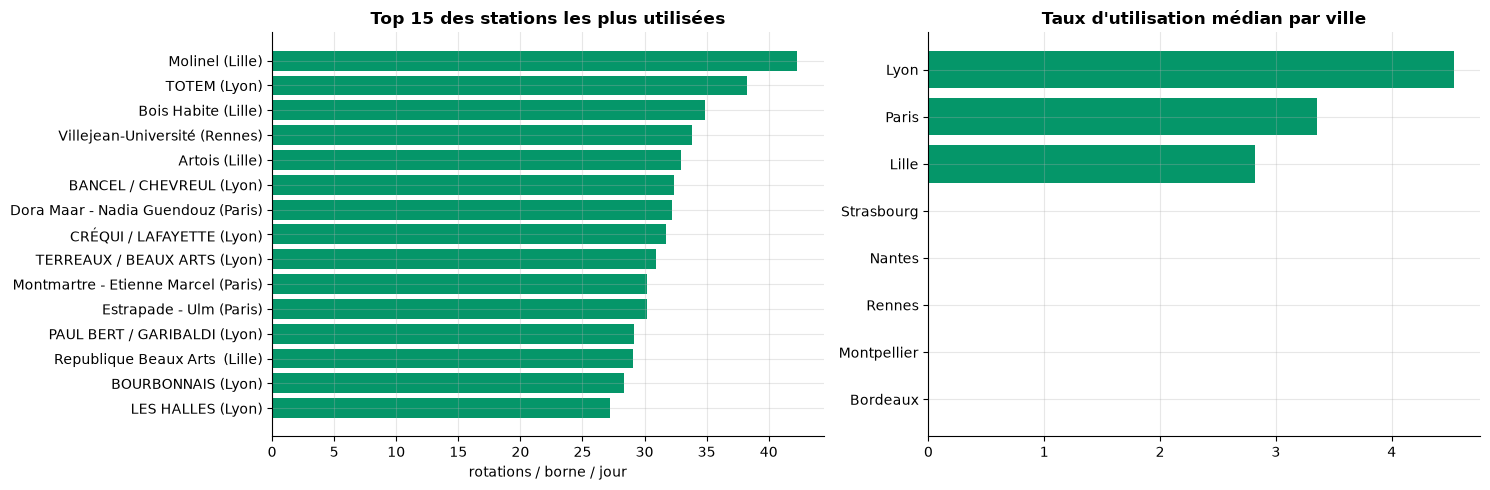

,station_name,city,capacity,movements,mouvements_par_heure,rotations_par_borne_jour,occupancy
0,Molinel,Lille,22,11.00,38.79,42.31,0.34
1,TOTEM,Lyon,16,9.00,25.51,38.27,0.14
2,Bois Habite,Lille,17,7.00,24.68,34.84,0.09
3,Villejean-Université,Rennes,25,10.00,35.26,33.85,0.30
4,Artois,Lille,18,7.00,24.68,32.91,0.28
5,BANCEL / CHEVREUL,Lyon,21,10.00,28.35,32.40,0.40
6,Dora Maar - Nadia Guendouz,Paris,30,12.00,40.30,32.24,0.58
7,CRÉQUI / LAFAYETTE,Lyon,15,7.00,19.84,31.75,0.15
8,TERREAUX / BEAUX ARTS,Lyon,11,5.00,14.16,30.90,0.20
9,Montmartre - Etienne Marcel,Paris,16,6.00,20.15,30.22,0.71


> Station la plus utilisée : **Molinel** (Lille), 42.3 rotations par borne et par jour. Réseau le plus intensif (médiane) : **Lyon**.

In [16]:
usage = M.station_usage(bikes, min_hours=min(1.0, span_h / 2))
top = usage.head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(top["station_name"] + " (" + top["city"] + ")", top["rotations_par_borne_jour"], color=plots.PALETTE["streaming"])
axes[0].invert_yaxis()
axes[0].set_xlabel("rotations / borne / jour")
axes[0].set_title("Top 15 des stations les plus utilisées")
med = usage.groupby("city")["rotations_par_borne_jour"].median().sort_values()
axes[1].barh(med.index, med.values, color=plots.PALETTE["streaming"])
axes[1].set_title("Taux d'utilisation médian par ville")
plt.tight_layout()
plt.show()
display(top[["station_name", "city", "capacity", "movements", "mouvements_par_heure", "rotations_par_borne_jour", "occupancy"]])
say(f"Station la plus utilisée : **{top.iloc[0]['station_name']}** ({top.iloc[0]['city']}), "
    f"{top.iloc[0]['rotations_par_borne_jour']:.1f} rotations par borne et par jour. "
    f"Réseau le plus intensif (médiane) : **{med.index[-1]}**.")

**Interprétation.**
- Les stations les plus utilisées sont typiquement des **pôles d'échanges** (grandes gares, nœuds de métro), des **quartiers d'affaires** et des **zones étudiantes** : les flux pendulaires s'y concentrent.
- Le taux médian par ville compare l'**intensité d'usage** des réseaux indépendamment de leur taille. Vélib' a le plus de stations, mais pas forcément les bornes les plus sollicitées.
- L'indicateur se stabilise au bout de quelques jours de collecte. Sur une fenêtre de quelques heures, il reflète surtout l'heure à laquelle on a collecté.

## Q2. Peut-on identifier des zones où l'offre de vélos est insuffisante ?

**Méthode.** On découpe la ville en mailles d'environ 1 km (0,01°). Une maille est en **sous-offre** si ses stations sont **vides plus de 25 % du temps** ou proposent **moins de 2 vélos en moyenne**.

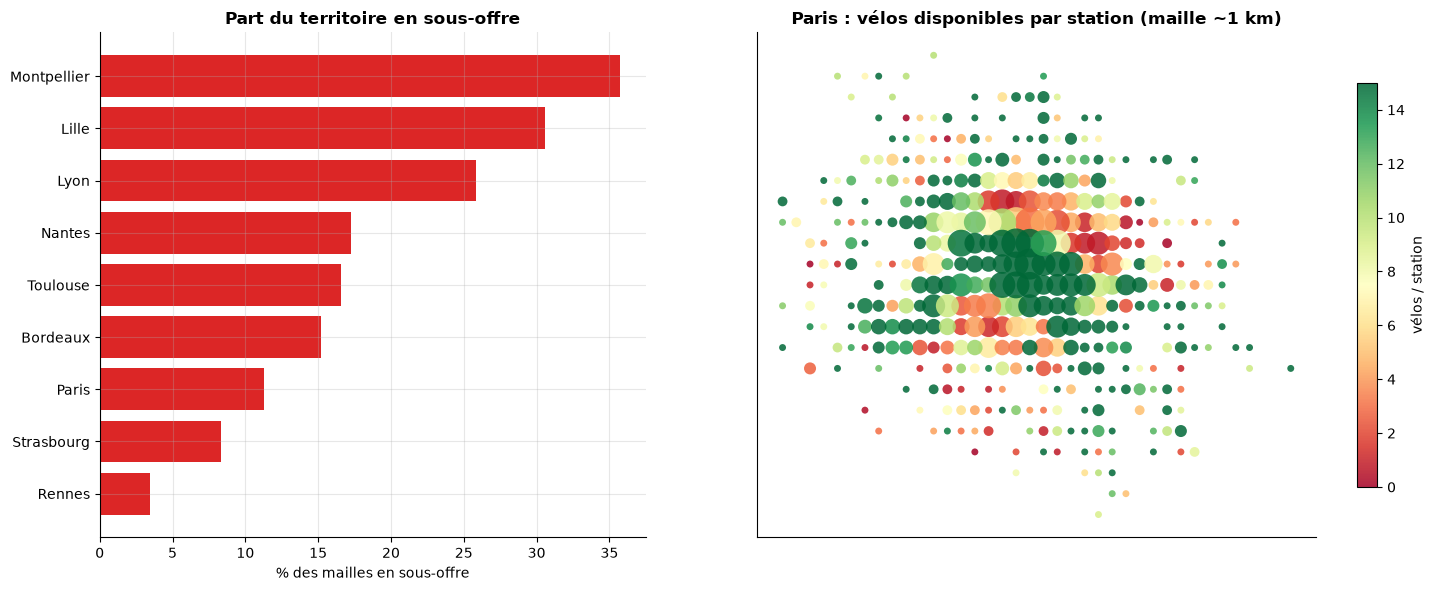

,city,cell_lat,cell_lon,stations,capacite,velos_moy_par_station,part_temps_vide,sous_offre
0,Toulouse,43.65,1.45,1,13,0.00,1.00,True
1,Bordeaux,44.83,-0.65,1,18,0.00,1.00,True
2,Paris,48.77,2.31,1,22,0.00,1.00,True
3,Montpellier,43.63,3.87,1,12,0.00,1.00,True
4,Paris,48.93,2.26,1,20,0.00,1.00,True
5,Strasbourg,48.58,7.72,1,12,0.00,1.00,True
6,Paris,48.92,2.29,1,30,0.00,1.00,True
7,Paris,48.88,2.43,1,30,0.00,1.00,True
8,Lyon,45.80,4.82,1,12,0.00,1.00,True
9,Paris,48.86,2.19,1,30,0.00,1.00,True


> 164 mailles sur 970 sont en sous-offre. Ville la plus touchée : **Montpellier** (36% des mailles).

In [17]:
zones = M.supply_gaps(bikes)
share = zones.groupby("city").agg(mailles=("sous_offre", "size"), part_sous_offre=("sous_offre", "mean")).sort_values("part_sous_offre")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(share.index, share["part_sous_offre"] * 100, color="#dc2626")
axes[0].set_xlabel("% des mailles en sous-offre")
axes[0].set_title("Part du territoire en sous-offre")
paris = zones[zones["city"] == "Paris"].rename(columns={"cell_lat": "latitude", "cell_lon": "longitude"})
if not paris.empty:
    plots.geo_scatter(axes[1], paris, "velos_moy_par_station", cmap="RdYlGn", size=paris["stations"] * 25,
                      vmin=0, vmax=15, title="Paris : vélos disponibles par station (maille ~1 km)", label="vélos / station")
plt.tight_layout()
plt.show()
display(zones[zones["sous_offre"]].head(15))
say(f"{int(zones['sous_offre'].sum())} mailles sur {len(zones)} sont en sous-offre. "
    f"Ville la plus touchée : **{share.index[-1]}** ({share['part_sous_offre'].iloc[-1]:.0%} des mailles).")

**Interprétation.**
- Les zones en sous-offre se situent typiquement :
  - **en hauteur** (Montmartre, Belleville, Croix-Rousse à Lyon), car les usagers descendent à vélo mais remontent rarement ;
  - **en périphérie résidentielle le matin**, quand les vélos partent vers le centre ;
  - **au centre le soir**, avec le mouvement inverse.
- Une sous-offre **chronique**, présente à toute heure, signale un **manque de vélos ou de stations** : c'est un sujet d'investissement. Une sous-offre **ponctuelle** relève plutôt du **rééquilibrage** (Q5).

## Q3. Quels sont les pics d'utilisation journaliers du réseau ?

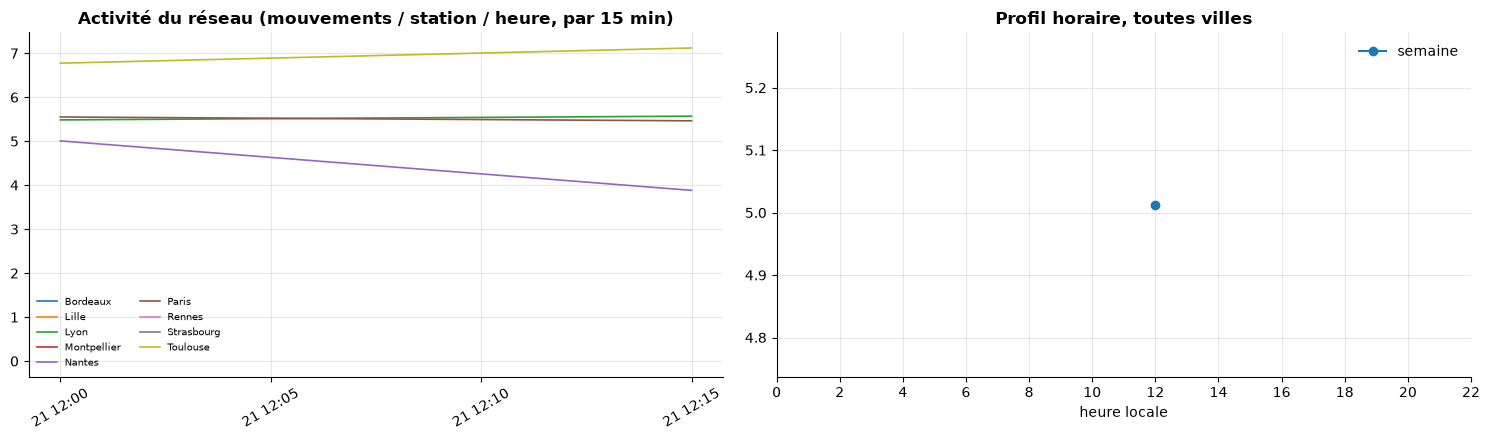

,city,weekend,hour,movements,hours,activite
0,Bordeaux,False,12,103.00,62.96,1.64
1,Lille,False,12,358.00,75.44,4.75
2,Lyon,False,12,899.00,160.58,5.60
3,Montpellier,False,12,4.00,14.73,0.27
4,Nantes,False,12,64.00,19.96,3.21
5,Paris,False,12,2445.00,450.84,5.42
6,Rennes,False,12,66.00,16.17,4.08
7,Strasbourg,False,12,0.00,11.33,0.00
8,Toulouse,False,12,431.00,59.74,7.21


> Seulement 1 heures de la journée sont couvertes : laissez tourner le collecteur au moins 24 h (idéalement une semaine) pour obtenir le profil complet.

In [18]:
act = M.network_activity(bikes)
profile = M.hourly_profile(bikes)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for city, g in act.groupby("city"):
    axes[0].plot(g["slot"], g["activite"].rolling(2, min_periods=1).mean(), lw=1.2, label=city)
axes[0].set_title("Activité du réseau (mouvements / station / heure, par 15 min)")
axes[0].legend(fontsize=7, ncol=2)
axes[0].tick_params(axis="x", rotation=30)

total = bikes.groupby(["weekend", "hour"]).agg(m=("movements", "sum"), h=("interval_h", "sum"))
total["activite"] = total["m"] / total["h"]
for wk, g in total.reset_index().groupby("weekend"):
    axes[1].plot(g["hour"], g["activite"], marker="o", label="week-end" if wk else "semaine")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("heure locale")
axes[1].set_title("Profil horaire, toutes villes")
axes[1].legend()
plt.tight_layout()
plt.show()

peaks = M.peak_hours(profile)
display(peaks)
hours_covered = bikes["hour"].nunique()
if hours_covered < 20:
    say(f"Seulement {hours_covered} heures de la journée sont couvertes : laissez tourner le collecteur au moins 24 h "
        "(idéalement une semaine) pour obtenir le profil complet.")
else:
    pk = total.reset_index()
    wd = pk[~pk["weekend"]].sort_values("activite", ascending=False)
    say(f"Pics en semaine : **{', '.join(str(h) + 'h' for h in wd['hour'].head(3))}**.")

**Interprétation.**
- En **semaine**, le profil attendu est **bimodal** : un pic le matin (8-9 h, trajets domicile-travail), un pic plus étalé le soir (17-19 h), et un plateau secondaire à midi.
- Le **week-end**, l'usage est plus tardif et plus étalé (14-18 h, usage loisir).
- Ces pics dimensionnent les besoins de **rééquilibrage** : il faut que les stations résidentielles soient pleines avant 8 h et que les stations de bureaux puissent absorber les retours.

## Q4. Existe-t-il des déséquilibres géographiques dans la disponibilité des vélos ?

**Méthode.** On mesure le taux de remplissage (vélos / (vélos + places libres)) selon la distance au centre-ville et le moment de la journée.

moment                            journée
city        anneau                       
Bordeaux    hyper-centre <1,5 km     0.32
            centre 1,5-4 km          0.36
            périphérie 4-8 km        0.32
Lille       hyper-centre <1,5 km     0.26
            centre 1,5-4 km          0.19
            périphérie 4-8 km        0.31
            banlieue >8 km           0.23
Lyon        hyper-centre <1,5 km     0.38
            centre 1,5-4 km          0.36
            périphérie 4-8 km        0.38
            banlieue >8 km           0.60
Montpellier hyper-centre <1,5 km     0.18
            centre 1,5-4 km          0.30
            périphérie 4-8 km        0.71
            banlieue >8 km           0.46
Nantes      hyper-centre <1,5 km     0.45
            centre 1,5-4 km          0.34
Paris       hyper-centre <1,5 km     0.64
            centre 1,5-4 km          0.37
            périphérie 4-8 km        0.35
            banlieue >8 km           0.45
Rennes      hyper-centre <1,5 km     0.36
            centre 1,5-4 km          0.33
            périphérie 4-8 km        0.40
Strasbourg  hyper-centre <1,5 km     0.32
            centre 1,5-4 km          0.42
            périphérie 4-8 km        0.60
            banlieue >8 km           0.67
Toulouse    hyper-centre <1,5 km     0.40
            centre 1,5-4 km          0.29
            périphérie 4-8 km        0.47
            banlieue >8 km           0.43

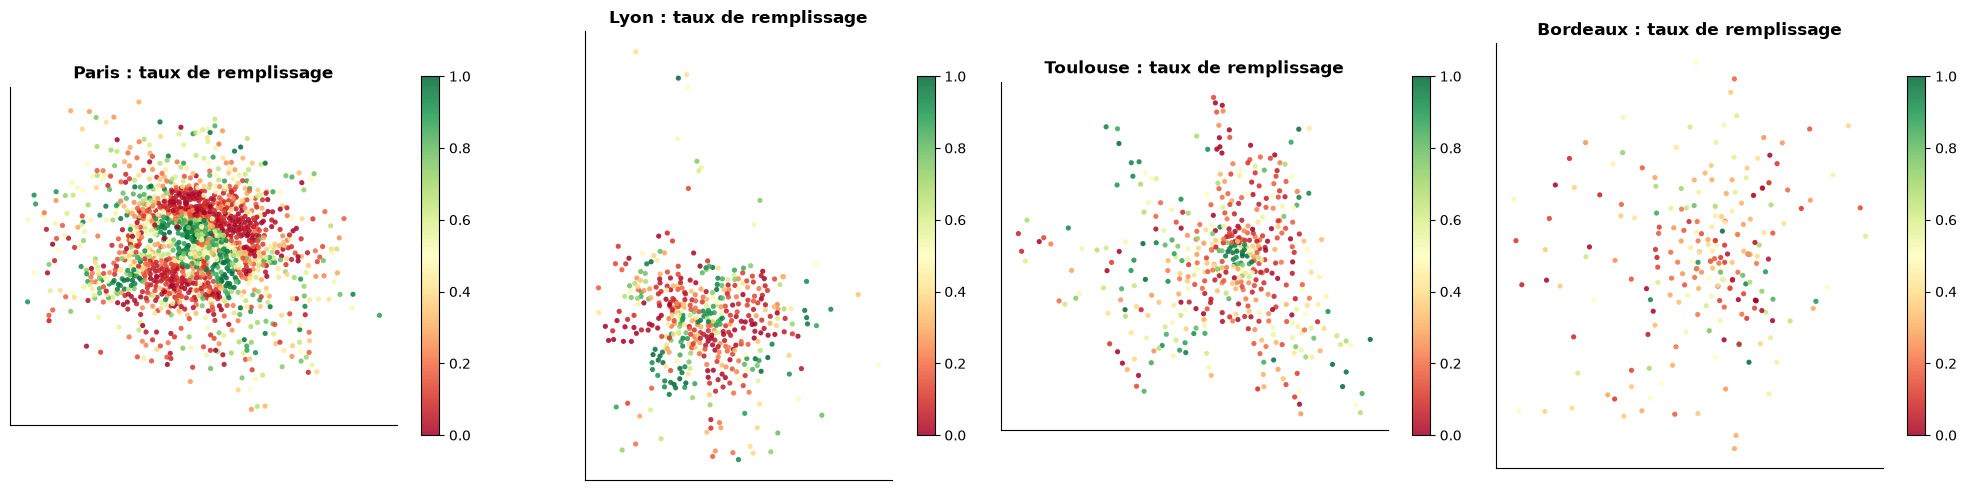

,remplissage_moyen,dispersion_entre_stations
city,,
Lyon,0.38,0.33
Paris,0.40,0.32
Toulouse,0.38,0.31
Nantes,0.41,0.28
Montpellier,0.26,0.25
Bordeaux,0.34,0.24
Strasbourg,0.48,0.21
Rennes,0.35,0.21
Lille,0.23,0.19


> Réseau le plus déséquilibré (dispersion du remplissage entre stations) : **Lyon** (écart-type 0.33) ; le plus homogène : **Lille** (0.19).

In [19]:
balance = M.geographic_balance(bikes)
stations_bal = M.station_balance(bikes)
display(balance)

cities_to_map = [c for c in ["Paris", "Lyon", "Toulouse", "Bordeaux"] if c in stations_bal["city"].unique()]
fig, axes = plt.subplots(1, len(cities_to_map), figsize=(5 * len(cities_to_map), 5))
for ax, city in zip(np.atleast_1d(axes), cities_to_map):
    plots.geo_scatter(ax, stations_bal[stations_bal["city"] == city], "occupancy", cmap="RdYlGn", vmin=0, vmax=1,
                      size=14, title=f"{city} : taux de remplissage", label="")
plt.tight_layout()
plt.show()

spread = stations_bal.groupby("city")["occupancy"].agg(["mean", "std"]).sort_values("std", ascending=False)
display(spread.rename(columns={"mean": "remplissage_moyen", "std": "dispersion_entre_stations"}))
say(f"Réseau le plus déséquilibré (dispersion du remplissage entre stations) : **{spread.index[0]}** "
    f"(écart-type {spread['std'].iloc[0]:.2f}) ; le plus homogène : **{spread.index[-1]}** ({spread['std'].iloc[-1]:.2f}).")

**Interprétation.**
- Les cartes montrent souvent des **grappes** de stations vides (en rouge) et pleines (en vert) : le déséquilibre est **spatialement structuré**, pas aléatoire.
- Le tableau centre / périphérie × moment de la journée met en évidence l'effet **pendulaire** : la périphérie se vide le matin (rouge), le centre se remplit (vert), puis la situation s'inverse le soir.
- La dispersion entre stations résume l'ampleur du déséquilibre d'un réseau. Plus elle est forte, plus le rééquilibrage par camion est nécessaire.

## Q5. Peut-on détecter des stations critiques nécessitant un rééquilibrage ?

**Critère** : une station est **critique** si elle est vide (0 vélo) ou pleine (0 place) au moins **20 % du temps** observé. On calcule pour chacune le nombre de vélos à apporter (> 0) ou à retirer (< 0) pour revenir à 50 % de remplissage. La priorité vaut part du temps en défaut × capacité.

stations                              velos_a_deplacer                          
probleme    pleine (à délester) vide (à réapprovisionner) pleine (à délester) vide (à réapprovisionner)
city                                                                                                   
Bordeaux                      3                        19                 -13                       161
Lille                         0                        46                   0                       406
Lyon                         32                        75                -300                       685
Montpellier                   2                         8                  -7                        44
Nantes                        0                         8                   0                       107
Paris                        75                       177               -1126                      2994
Rennes                        0                         2                   0                        10
Strasbourg                    1                         2                  -2                        11

,station_name,city,capacity,bikes_moy,part_vide,part_pleine,probleme,velos_a_deplacer,priorite
0,Invalides - Quai d'Orsay,Paris,410,0.00,1.00,0.00,vide (à réapprovisionner),205,410.00
1,Concorde - Place de la Madeleine,Paris,409,0.00,1.00,0.00,vide (à réapprovisionner),204,409.00
2,Station Tour de France,Paris,200,0.00,1.00,0.00,vide (à réapprovisionner),100,200.00
3,Pau Casals - Neuve Tolbiac,Paris,78,77.60,0.00,0.80,pleine (à délester),-39,62.40
4,Granges aux Belles - Hôpital Saint-Louis,Paris,60,0.00,1.00,0.00,vide (à réapprovisionner),30,60.00
5,GARE DE NANTES SUD,Nantes,70,0.17,0.83,0.00,vide (à réapprovisionner),35,58.30
6,Place du Canada,Paris,58,57.00,0.00,1.00,pleine (à délester),-28,58.00
7,Filles Saint-Thomas - Place de la Bourse,Paris,58,0.00,1.00,0.00,vide (à réapprovisionner),29,58.00
8,Square Raymond Souplex,Paris,52,0.00,1.00,0.00,vide (à réapprovisionner),26,52.00
9,Place Ginette Hamelin,Paris,51,48.00,0.00,1.00,pleine (à délester),-22,51.00


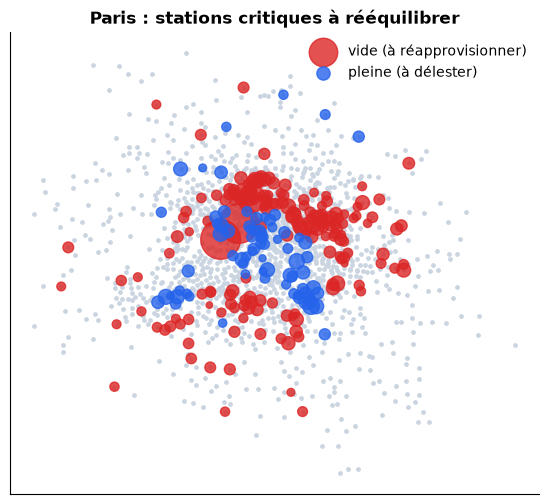

> **450 stations critiques** détectées : 335 à réapprovisionner (+4418 vélos) et 113 à délester (-1448 vélos).

In [20]:
critical = M.critical_stations(bikes, threshold=0.2)
if critical.empty:
    plots.no_data("aucune station critique sur la période (ou collecte trop courte)")
else:
    recap = critical.groupby(["city", "probleme"]).agg(stations=("station_id", "size"),
                                                       velos_a_deplacer=("velos_a_deplacer", "sum")).unstack(fill_value=0)
    display(recap)
    display(critical.head(20)[["station_name", "city", "capacity", "bikes_moy", "part_vide", "part_pleine",
                               "probleme", "velos_a_deplacer", "priorite"]])
    city = critical["city"].value_counts().index[0]
    fig, ax = plt.subplots(figsize=(7, 6))
    base = stations_bal[stations_bal["city"] == city]
    ax.scatter(base["longitude"], base["latitude"], s=6, c="#cbd5e1")
    c = critical[critical["city"] == city]
    for prob, color in [("vide (à réapprovisionner)", "#dc2626"), ("pleine (à délester)", "#2563eb")]:
        g = c[c["probleme"] == prob]
        ax.scatter(g["longitude"], g["latitude"], s=g["capacity"] * 2, c=color, label=prob, alpha=0.8)
    ax.set_aspect(1 / np.cos(np.radians(base["latitude"].mean())))
    ax.set_title(f"{city} : stations critiques à rééquilibrer")
    ax.legend(); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    plt.show()
    say(f"**{len(critical)} stations critiques** détectées : {int((critical['velos_a_deplacer'] > 0).sum())} à "
        f"réapprovisionner (+{int(critical.loc[critical['velos_a_deplacer'] > 0, 'velos_a_deplacer'].sum())} vélos) et "
        f"{int((critical['velos_a_deplacer'] < 0).sum())} à délester "
        f"({int(critical.loc[critical['velos_a_deplacer'] < 0, 'velos_a_deplacer'].sum())} vélos).")

**Interprétation.**
- Oui : la liste ci-dessus est une **feuille de route de rééquilibrage**, triée par priorité. Les équipes savent où aller, et avec combien de vélos.
- Les stations **vides** chroniques sont les cibles prioritaires, car elles font perdre des usagers. Les stations **pleines** empêchent de rendre son vélo, ce qui frustre l'usager et peut lui coûter des pénalités.
- En production, ce calcul tournerait **toutes les 15 minutes** sur la dernière heure de données pour piloter les tournées en temps réel. On pourrait aussi y ajouter une prévision : quelle station sera vide dans 30 minutes ?

<a id="3"></a>
# Partie 3 : Pollution urbaine (flux IoT)

**Source** : OpenAQ API v3, les capteurs de qualité de l'air (réseaux AASQA / EEA en France). Une **clé API gratuite** est nécessaire (`OPENAQ_API_KEY` dans `.env`).

## Ingestion

- `inventory.py` : inventaire de toutes les stations françaises (`iso=FR`), filtrées sur les polluants **PM2.5, PM10, NO₂, O₃, CO** et rattachées aux grandes villes.
- `collector.py` (**flux IoT simulé**) : toutes les 15 min, lecture de la dernière mesure de chaque capteur. Chaque mesure est émise comme un **message capteur indépendant** `{sensor_id, pollutant, timestamp, latitude, longitude, value, unit}`, comme sur un bus MQTT ou Kafka. Les messages sont archivés en JSON Lines (`bronze/openaq/stream/`) puis insérés dans `air_measurement`.
- `backfill.py` : historique horaire (`/sensors/{id}/hours`), nécessaire pour étudier les variations journalières et les épisodes.
- Le client respecte la limite du plan gratuit (60 requêtes par minute).
- Toutes les valeurs sont **normalisées en µg/m³** (conversion ppm/ppb par masse molaire).

In [21]:
air = data.air_measurements()
HAS_AIR = not air.empty
if not HAS_AIR:
    plots.no_data("ajoutez OPENAQ_API_KEY dans .env puis lancez `python -m urbanhub air-backfill --days 60` "
                  "et `python -m urbanhub air`. Les cellules de cette partie s'exécuteront alors automatiquement.")
else:
    say(f"{len(air):,} mesures, {air['sensor_id'].nunique()} capteurs, {air['location_id'].nunique()} stations, "
        f"{air['city'].nunique()} villes, du {air['ts'].min():%d/%m/%Y} au {air['ts'].max():%d/%m/%Y}.")
    display(air.groupby(["city", "pollutant"])["sensor_id"].nunique().unstack(fill_value=0))

⚠️  Pas encore de données : ajoutez OPENAQ_API_KEY dans .env puis lancez `python -m urbanhub air-backfill --days 60` et `python -m urbanhub air`. Les cellules de cette partie s'exécuteront alors automatiquement.


## Q1. Quelles zones présentent les niveaux de pollution les plus élevés ?

Les concentrations sont comparées au **seuil journalier OMS 2021** de chaque polluant (indice 1 = au niveau du seuil). On peut ainsi comparer des polluants différents.

In [22]:
if HAS_AIR:
    loc_levels = P.levels_by_location(air)
    city_levels = P.levels_by_city(air)
    display(city_levels)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    top_loc = loc_levels.head(15)
    axes[0].barh(top_loc["location_name"].str[:30] + " · " + top_loc["pollutant"], top_loc["indice_oms"], color=plots.PALETTE["iot"])
    axes[0].axvline(1, color="black", ls="--", lw=1)
    axes[0].invert_yaxis()
    axes[0].set_title("Stations les plus polluées (moyenne / seuil OMS)")
    no2 = loc_levels[loc_levels["pollutant"] == "no2"]
    if not no2.empty:
        plots.geo_scatter(axes[1], no2, "moyenne_ugm3", cmap="YlOrRd", size=40, title="NO₂ moyen par station", label="µg/m³")
    plt.tight_layout()
    plt.show()
    say(f"Zone la plus exposée : **{top_loc.iloc[0]['location_name']}** ({top_loc.iloc[0]['city']}) en "
        f"{config.POLLUTANTS[top_loc.iloc[0]['pollutant']]}, {top_loc.iloc[0]['indice_oms']:.1f} fois le seuil OMS.")

**Interprétation.**
- Les niveaux les plus élevés de **NO₂** se trouvent près des **axes routiers** et dans les grandes agglomérations (stations « trafic » : périphérique parisien, centres de Lyon et de Marseille). Le NO₂ est le traceur du trafic diesel.
- Les **particules** sont plus homogènes à l'échelle régionale (chauffage au bois, agriculture, transport longue distance).
- L'**ozone** est paradoxalement plus élevé en **périphérie et en zone rurale** : il se forme à distance des sources, et le NO émis en ville le détruit localement.

## Q2. Existe-t-il une variation journalière de la pollution ?

In [23]:
if HAS_AIR:
    cycle = P.daily_cycle(air)
    fig, ax = plt.subplots(figsize=(10, 4))
    for pol in cycle.columns:
        ax.plot(cycle.index, cycle[pol], marker="o", lw=1.5, label=config.POLLUTANTS.get(pol, pol))
    ax.axhline(1, color="black", lw=0.6)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("heure locale")
    ax.set_ylabel("concentration / moyenne du polluant")
    ax.set_title("Profil journalier moyen des polluants")
    ax.legend()
    plt.show()
    amp_air = P.daily_cycle_amplitude(air)
    display(amp_air)
    say("Heures de pic : " + ", ".join(f"{config.POLLUTANTS.get(p, p)} à {int(r.heure_pic)}h (×{r.ratio_pic_creux} vs creux)"
                                       for p, r in amp_air.iterrows()))

**Interprétation.**
- **NO₂** : profil **bimodal** calé sur le trafic, avec un pic le matin (7-9 h) et un pic plus fort le soir (19-22 h, quand la couche limite s'abaisse et piège la pollution), puis un creux l'après-midi.
- **O₃** : profil **inverse**, maximal l'après-midi (14-17 h), car il se forme sous l'effet du soleil (photochimie) à partir des NOx. C'est un polluant **secondaire**.
- **PM** : variation plus faible, avec des pics le soir et la nuit en hiver (chauffage au bois, inversion thermique).
- Oui, la variation journalière est forte. Elle reflète à la fois les **émissions humaines** (trafic) et la **météo** (ensoleillement, hauteur de mélange).

## Q3. Quels polluants sont les plus dominants dans la ville étudiée ?

On compare les polluants entre eux via l'indice OMS (concentration moyenne / seuil journalier OMS).

In [24]:
if HAS_AIR:
    dom = P.dominant_pollutants(air)
    display(dom)
    idx = dom.drop(columns="dominant")
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(idx) + 2))
    plots.heatmap(ax, idx.rename(columns=config.POLLUTANTS), cmap="YlOrRd", center=None,
                  title="Indice OMS moyen (1 = seuil journalier)")
    plt.show()
    main_city = air["city"].value_counts().index[0]
    say(f"Polluant dominant à **{main_city}** : **{dom.loc[main_city, 'dominant']}**. Répartition des polluants "
        f"dominants : {dom['dominant'].value_counts().to_dict()}.")

**Interprétation.**
- Rapporté aux seuils sanitaires, le **NO₂** et les **PM2.5** dominent en général dans les grandes villes françaises, avec des moyennes proches du seuil OMS, voire au-dessus. Les seuils OMS 2021 sont nettement plus stricts que les limites réglementaires européennes.
- L'**O₃** domine en été et dans le Sud (Marseille, Nice, Montpellier : fort ensoleillement).
- Le **CO** est aujourd'hui très en dessous des seuils : ce n'est plus un enjeu en air ambiant.

## Q4. Peut-on identifier des épisodes de pollution anormale ?

On utilise deux critères complémentaires sur les **moyennes journalières** :
- **sanitaire** : dépassement du seuil OMS journalier ;
- **statistique** : z-score *robuste* > 3,5, calculé avec la médiane et le MAD. Ces statistiques ne sont pas biaisées par les épisodes eux-mêmes, contrairement à la moyenne et à l'écart-type.

In [25]:
if HAS_AIR:
    episodes = P.pollution_episodes(air)
    dm = P.daily_means(air)
    pols = [p for p in ["pm25", "no2", "o3", "pm10"] if p in dm["pollutant"].unique()]
    fig, axes = plt.subplots(len(pols), 1, figsize=(13, 2.6 * len(pols)), sharex=True, squeeze=False)
    for ax, pol in zip(axes[:, 0], pols):
        g = dm[dm["pollutant"] == pol].groupby("day")["mean"].mean()
        ax.plot(g.index, g.values, color=plots.PALETTE["iot"])
        ax.axhline(config.WHO_DAILY_GUIDELINES[pol], color="black", ls="--", lw=1, label="seuil OMS")
        e = episodes[(episodes["pollutant"] == pol) & episodes["anomalie_stat"]]
        ax.scatter(e["day"], e["moyenne_jour_ugm3"], color="#dc2626", s=18, zorder=3, label="anomalie statistique")
        ax.set_ylabel(f"{config.POLLUTANTS[pol]} µg/m³")
        ax.legend(loc="upper right", fontsize=8)
    axes[0, 0].set_title("Moyennes journalières (toutes villes) et épisodes détectés")
    plt.tight_layout()
    plt.show()
    display(episodes.head(20))
    say(f"{int(episodes['depasse_oms'].sum())} jours-ville-polluant au-dessus du seuil OMS, dont "
        f"{int(episodes['anomalie_stat'].sum())} anomalies statistiques marquées.")

**Interprétation.**
- Les **épisodes statistiques** sont généralement **synchrones entre villes**, ce qui signe un phénomène météorologique de grande échelle : anticyclone hivernal pour les PM, vague de chaleur pour l'O₃.
- Les **dépassements OMS** sont nombreux, en particulier pour les PM2.5 et le NO₂ : même hors épisode, l'exposition chronique dépasse les recommandations sanitaires.
- Les **pics horaires isolés** (`P.hourly_anomalies`) révèlent plutôt des événements **locaux** : feux, chantiers, bouchons, ou parfois un capteur défaillant. Ils sont à valider avant de déclencher une alerte.

<a id="4"></a>
# Partie 4 : Analyse croisée Météo × Mobilité × Air

**Grain commun** : (ville, heure UTC).

**Source météo** : la vue `v_weather_city_hourly` fusionne la **NOAA** (jusqu'à la fin de l'archive, en 2025) et **Open-Meteo** pour la période récente. On dispose ainsi de la météo correspondant aux relevés vélos et pollution actuels, avec les mêmes variables et les mêmes unités.

**Normalisation de l'usage vélo** : l'usage dépend d'abord de l'heure (pointes). Pour isoler l'effet météo, on calcule un **indice d'usage** = activité observée / activité moyenne **à la même heure et pour le même type de jour**. Un indice de 1,2 signifie 20 % d'usage en plus que d'habitude à ce moment-là.

In [26]:
air_city = data.air_city_hourly()
aw = X.air_wide(air_city) if not air_city.empty else pd.DataFrame()
POLS = [p for p in config.POLLUTANTS if p in aw.columns]

bh = X.bike_hourly(act)[["city", "ts", "activite", "indice_usage"]] if not status.empty else pd.DataFrame()
start = min([d for d in [bh["ts"].min() if not bh.empty else None, air_city["ts"].min() if not air_city.empty else None] if d is not None],
            default=None)
weather_all = data.weather_city_hourly(start=start) if start is not None else pd.DataFrame()
print("Météo disponible :", weather_all.groupby("source").size().to_dict() if not weather_all.empty else "aucune")

Météo disponible : {'open-meteo': 11}


## Q1. Existe-t-il une relation entre conditions météorologiques et pollution ?

In [27]:
if not aw.empty:
    wp_weather = data.weather_city_hourly(start=air_city["ts"].min())
    wp = X.merge_sources(wp_weather, air=aw)
    print(f"{len(wp):,} heures-ville communes météo × pollution")
    corr_wp = X.weather_pollution_correlations(wp, POLS)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    plots.heatmap(axes[0], corr_wp.rename(columns=config.POLLUTANTS), title="Corrélation de Spearman météo × polluants")
    by_wind = X.pollution_by_wind(wp, POLS)
    (by_wind / by_wind.iloc[0]).rename(columns=config.POLLUTANTS).plot(ax=axes[1], marker="o")
    axes[1].set_title("Concentration selon le vent (base 1 = vent < 2 m/s)")
    by_temp = X.pollution_by_temperature(wp, POLS)
    by_temp.rename(columns=config.POLLUTANTS).plot(ax=axes[2], marker="o")
    axes[2].set_title("Concentration (µg/m³) selon la température")
    axes[2].tick_params(axis="x", rotation=35)
    plt.tight_layout()
    plt.show()
    display(by_wind)
else:
    plots.no_data("données OpenAQ nécessaires (Partie 3)")

⚠️  Pas encore de données : données OpenAQ nécessaires (Partie 3)


**Interprétation.**
- **Vent** : c'est le facteur le plus net. Les concentrations de NO₂ et de PM **chutent quand le vent forcit**, parce que la pollution est dispersée. Par vent calme, elle s'accumule. C'est le même mécanisme que pour le brouillard en Partie 1 Q2.
- **Température** : l'**O₃ augmente fortement avec la chaleur** (photochimie). C'est le risque combiné canicule + ozone. Le NO₂ et les PM sont au contraire plus élevés par **temps froid** (chauffage, inversions thermiques).
- **Pluie** : elle lessive l'atmosphère et fait baisser les particules.
- **Pression élevée** (anticyclone) : elle va avec stagnation et pollution. C'est le terrain des épisodes hivernaux.

## Q2. Les conditions météo influencent-elles l'utilisation des vélos urbains ?

In [28]:
wb = X.merge_sources(weather_all, bikes=bh) if not bh.empty and not weather_all.empty else pd.DataFrame()
if wb.empty or wb["indice_usage"].notna().sum() < 10:
    plots.no_data("pas encore assez d'heures communes vélos × météo : laissez tourner `python -m urbanhub bikes` "
                  "plusieurs jours puis relancez `python -m urbanhub weather-recent`")
else:
    effects = X.weather_bike_effects(wb)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key, title in zip(axes, ["pluie", "temperature_classe", "vent_classe"], ["pluie", "température", "vent"]):
        t = effects[key]
        ax.bar(t.index.astype(str), t["mean"], color=plots.PALETTE["cross"])
        ax.axhline(1, color="black", ls="--", lw=1)
        ax.set_title(f"Indice d'usage selon la {title}" if key != "vent_classe" else "Indice d'usage selon le vent")
    plt.tight_layout()
    plt.show()
    display(effects["correlations"])
    rain = effects["pluie"]["mean"]
    if {"pluie", "sec"} <= set(rain.index):
        say(f"Par temps de pluie, l'usage est à **{rain['pluie']:.2f}** fois son niveau habituel, contre {rain['sec']:.2f} par temps sec "
            f"(effet de {(rain['pluie'] / rain['sec'] - 1):+.0%}).")

⚠️  Pas encore de données : pas encore assez d'heures communes vélos × météo : laissez tourner `python -m urbanhub bikes` plusieurs jours puis relancez `python -m urbanhub weather-recent`


**Interprétation.**
- La **pluie** est le facteur le plus pénalisant pour le vélo. Avec l'indice d'usage, on mesure l'effet « toutes choses égales par ailleurs » à heure identique.
- La **température** a un effet en cloche : l'usage est faible par grand froid, optimal entre 15 et 25 °C, puis légèrement moindre en forte chaleur.
- Le **vent fort** décourage aussi, mais moins que la pluie.
- Avec seulement quelques jours de collecte, ces effets restent indicatifs. Il faudrait plusieurs semaines, couvrant des météos variées, pour les quantifier de façon fiable.

## Q3. Peut-on identifier des conditions météorologiques favorables à la mobilité douce ?

In [29]:
if not wb.empty and wb["indice_usage"].notna().sum() >= 10:
    fav = X.favorable_conditions(wb, min_hours=2)
    display(fav)
    best = fav[fav["favorable"]]
    if not best.empty:
        b = best.index[0]
        say(f"Conditions les plus favorables observées : température **{b[0]}**, temps **{b[1]}**, **{b[2]}** "
            f"(indice {best['mean'].iloc[0]:.2f}, soit {best['mean'].iloc[0] - 1:+.0%} d'usage).")
else:
    plots.no_data("même prérequis que Q2")

⚠️  Pas encore de données : même prérequis que Q2


**Interprétation.**
- Le combo **sec + 15-25 °C + vent calme** est en général le plus favorable. C'est le « beau temps » des intersaisons (printemps, début d'automne).
- Cette information est **actionnable** : prévoir plus de vélos disponibles (rééquilibrage anticipé) les jours de beau temps annoncés, et communiquer sur la mobilité douce lors de ces fenêtres.
- Elle rejoint aussi la Partie 3 : les jours chauds, sans vent et ensoleillés sont favorables au vélo, mais aussi à l'**ozone**. Le vélo y est un levier de réduction des émissions, mais l'effort physique augmente l'exposition des cyclistes.

## Q4. Existe-t-il des périodes où mobilité, pollution et météo interagissent fortement ?

**Méthode.** Par ville et par jour, on calcule le z-score de l'usage vélo, de la pollution (NO₂) et de la météo (température). Une **journée d'interaction forte** combine des écarts marqués (|z| ≥ 1) sur les trois dimensions à la fois. On complète par la matrice de corrélation horaire des trois familles de variables.

In [30]:
full = X.merge_sources(weather_all, bikes=bh, air=aw) if not (bh.empty or aw.empty or weather_all.empty) else pd.DataFrame()
if full.empty or full["indice_usage"].notna().sum() < 10:
    plots.no_data("il faut simultanément des relevés vélos, des mesures OpenAQ et la météo sur la même période")
else:
    mat = X.hourly_interaction_matrix(full, POLS)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    plots.heatmap(ax, mat, title="Corrélations horaires mobilité × météo × pollution")
    plt.show()
    inter = X.daily_interactions(full, pollutant="no2" if "no2" in POLS else POLS[0])
    display(inter.sort_values("z_usage"))
    if "interaction_forte" in inter:
        strong = inter[inter["interaction_forte"]]
        say(f"{len(strong)} journées-ville d'interaction forte détectées." if len(strong)
            else "Pas encore de journée combinant de forts écarts sur les trois dimensions.")

⚠️  Pas encore de données : il faut simultanément des relevés vélos, des mesures OpenAQ et la météo sur la même période


**Interprétation attendue et lecture.**
- Les situations d'**interaction forte** typiques sont les suivantes :
  - **anticyclone froid et calme** : forte pollution (NO₂, PM), peu de vent, usage du vélo en baisse ;
  - **vague de chaleur** : pic d'O₃, usage du vélo en hausse le soir mais en baisse aux heures chaudes ;
  - **jour de pluie et de vent** : air propre (lessivage, dispersion), usage du vélo au plus bas.
- La matrice horaire fait apparaître ces chaînes causales. Le **vent** est corrélé négativement à la pollution, la **pluie** négativement à l'usage, et l'usage vélo n'est que faiblement lié à la pollution, car il reste minoritaire dans le trafic total.
- Pour le décideur, ces journées sont celles où un **pilotage combiné** a le plus d'impact : gratuité des vélos les jours de pic de pollution, alertes canicule + ozone, renfort de rééquilibrage.

<a id="5"></a>
# 5. Conclusion et limites

### Ce que la plateforme UrbanHub apporte
| Livrable | Où |
|---|---|
| 01 Scripts de collecte | `urbanhub/batch`, `urbanhub/streaming`, `urbanhub/iot`, `urbanhub/enrichment` |
| 02 Stockage structuré | Data Lake MinIO (bronze/silver) + PostgreSQL (`sql/init.sql`, schéma `urbanhub`) |
| 03 Pipeline de traitement | décodage et nettoyage NOAA, normalisation CityBikes et OpenAQ, agrégats SQL, vues gold |
| 04-06 Analyses, visualisations, interprétations | ce notebook (`urbanhub/analysis/*` : une fonction par question) |

### Principaux enseignements
- **Météo** : les anomalies (chaleur 2022, 2023, 2025 ; froid de décembre 2022) sont détectées de façon fiable. La visibilité est gouvernée par la pluie et surtout par les situations anticycloniques calmes. Le cycle saisonnier oppose climats méditerranéen, continental et océanique.
- **Mobilité** : l'usage est pendulaire, les déséquilibres sont spatialement structurés, et une liste priorisée de stations à rééquilibrer peut être produite en continu.
- **Air** : le NO₂ (trafic) et les PM2.5 dominent par rapport aux seuils sanitaires. L'O₃ est le polluant de la chaleur.
- **Croisé** : le vent et la stabilité atmosphérique relient météo et pollution, et la pluie et la température relient météo et vélo.

### Limites
- L'archive NOAA s'arrête en août 2025. Open-Meteo prend le relais pour la période de collecte.
- CityBikes est uniquement temps réel : l'historique se construit avec le collecteur. Les mouvements sont une **borne basse** des trajets. Certains flux (ex. Marseille) sont défaillants et détectés par le contrôle qualité.
- OpenAQ : la couverture varie selon les villes, et le plan gratuit limite le débit. Le flux IoT est **simulé** par interrogation régulière.

### Pistes d'évolution
- Orchestration (Airflow, Prefect) et collecteurs en conteneurs (`docker compose --profile collectors up`).
- Vrai bus de messages (Kafka, MQTT) pour le flux IoT.
- Tableaux de bord **Metabase** branchés sur les vues `urbanhub.v_*`.
- Modèles prédictifs : disponibilité des vélos à 30 minutes, prévision des pics d'O₃.